## Transfering Learning 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Dense, Flatten
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

### 1. Feature-Extraction 

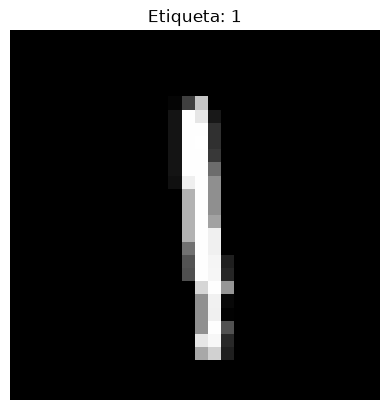

In [21]:
(x_train_original, y_train_original), (x_test_original, y_test_original) = (
    tf.keras.datasets.mnist.load_data()
)

# Visualizamos una imagen original
plt.imshow(x_train_original[8], cmap="gray")
plt.title(f"Etiqueta: {y_train_original[8]}")
plt.axis("off")
plt.show()

In [22]:
# División train/validation: 80 % / 20 %
x_train_original, x_val_original, y_train_original, y_val_original = (
    train_test_split(
        x_train_original,
        y_train_original,
        test_size=0.2,
        random_state=42,
        stratify=y_train_original
    )
)

print("X_train:", x_train_original.shape)
print("X_val:", x_val_original.shape)
print("X_test:", x_test_original.shape)

X_train: (48000, 28, 28)
X_val: (12000, 28, 28)
X_test: (10000, 28, 28)


In [23]:
# Preprocesamiento de los datos 

# VGG16 necesita imágenes con 3 canales RGB.
# Redimensionamos MNIST de 28x28 a 32x32 y replicamos
# el canal de escala de grises en los tres canales.
#
# Conservamos los píxeles en el rango 0-255 para aplicar
# posteriormente preprocess_input de VGG16.

# %%
def preparar_imagenes_vgg16(imagenes):
    """
    Convierte imágenes MNIST de (n, 28, 28) a (n, 32, 32, 3).
    Devuelve imágenes uint8 en el rango 0-255.
    """
    imagenes = tf.convert_to_tensor(imagenes)

    # Añadimos el canal de escala de grises
    imagenes = imagenes[..., tf.newaxis]

    # Redimensionamos a 32x32
    imagenes = tf.image.resize(
        imagenes,
        size=(32, 32),
        method="bilinear"
    )

    # Replicamos el canal gris para obtener RGB
    imagenes = tf.repeat(imagenes, repeats=3, axis=-1)

    # Conservamos el rango de píxeles 0-255
    imagenes = tf.cast(
        tf.clip_by_value(tf.round(imagenes), 0, 255),
        tf.uint8
    )

    return imagenes.numpy()


x_train = preparar_imagenes_vgg16(x_train_original)
x_val = preparar_imagenes_vgg16(x_val_original)
x_test = preparar_imagenes_vgg16(x_test_original)

# One-hot encoding de las etiquetas
y_train = to_categorical(y_train_original, num_classes=10)
y_val = to_categorical(y_val_original, num_classes=10)
y_test = to_categorical(y_test_original, num_classes=10)

print("X_train:", x_train.shape)
print("X_val:", x_val.shape)
print("X_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (48000, 32, 32, 3)
X_val: (12000, 32, 32, 3)
X_test: (10000, 32, 32, 3)
y_train: (48000, 10)
y_val: (12000, 10)
y_test: (10000, 10)


In [24]:
# ### 4. Data Augmentation
#
# El aumento de datos se aplica únicamente a train.
# preprocess_input realiza el preprocesamiento específico
# que espera VGG16 preentrenada con ImageNet.

# %%
datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.5,
    fill_mode="nearest"
)

# Generador sin aumentos aleatorios para evaluar train
eval_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Preprocesamos validation y test sin aplicar aumentos
x_val_processed = preprocess_input(
    x_val.astype("float32")
)
x_test_processed = preprocess_input(
    x_test.astype("float32")
)

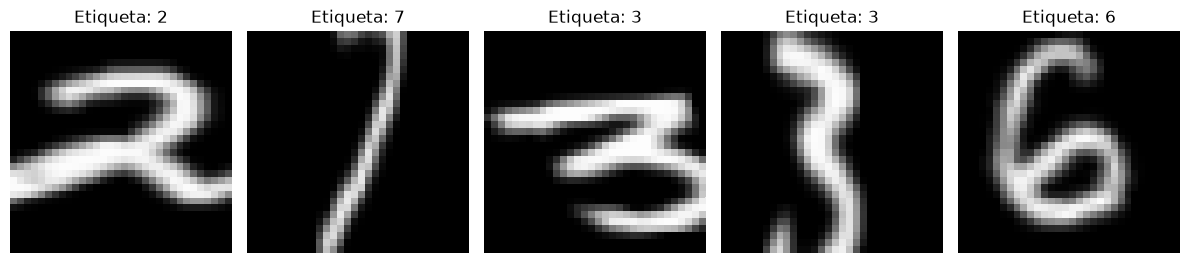

In [25]:
# ### 5. Visualización de imágenes aumentadas

# %%
generator = datagen.flow(
    x_train,
    y_train,
    batch_size=5,
    shuffle=True,
    seed=42
)

batch_images, batch_labels = next(generator)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Invertimos aproximadamente el preprocesamiento
    # para visualizar las imágenes en RGB.
    imagen = batch_images[i] + np.array([103.939, 116.779, 123.68])
    imagen = np.clip(imagen[..., ::-1], 0, 255).astype("uint8")

    ax.imshow(imagen)
    ax.set_title(f"Etiqueta: {np.argmax(batch_labels[i])}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ### 6. Carga de VGG16 preentrenada
#
# include_top=False elimina el clasificador original de ImageNet.
# Utilizaremos la base convolucional para extraer características
# y añadiremos una cabeza clasificadora para las 10 clases de MNIST.

# %%
pre_trained_model = VGG16(
    input_shape=(32, 32, 3),
    include_top=False,
    weights='imagenet'
)

pre_trained_model.summary()

ValueError: When setting `include_top=True` and loading `imagenet` weights, `input_shape` should be (224, 224, 3).  Received: input_shape=(32, 32, 3)

In [27]:
# ### 7. Congelación de las capas convolucionales

for layer in pre_trained_model.layers:
    layer.trainable = False  # congelar

pre_trained_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [28]:
model = Sequential()
model.add(pre_trained_model)
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [29]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# ### 10. Entrenamiento: Feature Extraction

# %%
batch_size = 64

train_generator = datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=True,
    seed=42
)

history = model.fit(
    train_generator,
    epochs=15,
    validation_data=(x_val_processed, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 128s 169ms/step - accuracy: 0.7593 - loss: 1.0541 - val_accuracy: 0.8718 - val_loss: 0.4129
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 142s 169ms/step - accuracy: 0.8362 - loss: 0.5519 - val_accuracy: 0.8795 - val_loss: 0.3737
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 132s 176ms/step - accuracy: 0.8541 - loss: 0.4624 - val_accuracy: 0.9047 - val_loss: 0.3019
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 128s 171ms/step - accuracy: 0.8673 - loss: 0.4079 - val_accuracy: 0.8797 - val_loss: 0.3614
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 134s 179ms/step - accuracy: 0.8719 - loss: 0.3926 - val_accuracy: 0.9103 - val_loss: 0.2791
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 134s 178ms/step - accuracy: 0.8755 - loss: 0.3793 - val_accuracy: 0.8935 - val_loss: 0.3585
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 128s 171ms/step - accuracy: 0.8814 - loss: 0.3630 - val_accuracy: 0.9064 - val_loss: 0.2861
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 151s 201ms/step - accuracy: 0.8845 -

In [30]:
# ### 11. Evaluación sobre train y validation
#
# Evaluamos train sin aumentos aleatorios, para que la comparación
# con validation sea más consistente.

# %%
train_eval_generator = eval_datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=False
)

train_loss, train_accuracy = model.evaluate(
    train_eval_generator,
    verbose=1
)

val_loss, val_accuracy = model.evaluate(
    x_val_processed,
    y_val,
    batch_size=batch_size,
    verbose=1
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print("-" * 80)
print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

750/750 ━━━━━━━━━━━━━━━━━━━━ 103s 136ms/step - accuracy: 0.9283 - loss: 0.2188
188/188 ━━━━━━━━━━━━━━━━━━━━ 25s 133ms/step - accuracy: 0.9222 - loss: 0.2427
Train Loss: 0.2188
Validation Loss: 0.2427
--------------------------------------------------------------------------------
Train Accuracy: 0.9283
Validation Accuracy: 0.9222


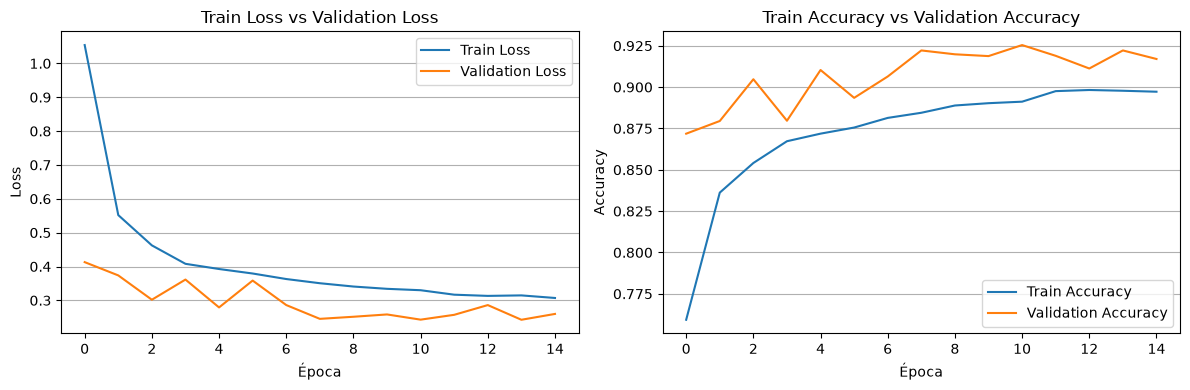

In [31]:
# ### 12. Visualización de las curvas de aprendizaje

# %%
df_history = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pérdida
axes[0].plot(df_history["loss"], label="Train Loss")
axes[0].plot(df_history["val_loss"], label="Validation Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].set_title("Train Loss vs Validation Loss")
axes[0].grid(True, axis="y")
axes[0].legend()

# Exactitud
axes[1].plot(df_history["accuracy"], label="Train Accuracy")
axes[1].plot(df_history["val_accuracy"], label="Validation Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Train Accuracy vs Validation Accuracy")
axes[1].grid(True, axis="y")
axes[1].legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1185
           1       0.99      0.96      0.98      1348
           2       0.87      0.93      0.90      1192
           3       0.95      0.84      0.89      1226
           4       0.95      0.92      0.93      1168
           5       0.89      0.87      0.88      1084
           6       0.91      0.97      0.94      1184
           7       0.93      0.92      0.93      1253
           8       0.83      0.94      0.88      1170
           9       0.94      0.89      0.92      1190

    accuracy                           0.92     12000
   macro avg       0.92      0.92      0.92     12000
weighted avg       0.92      0.92      0.92     12000



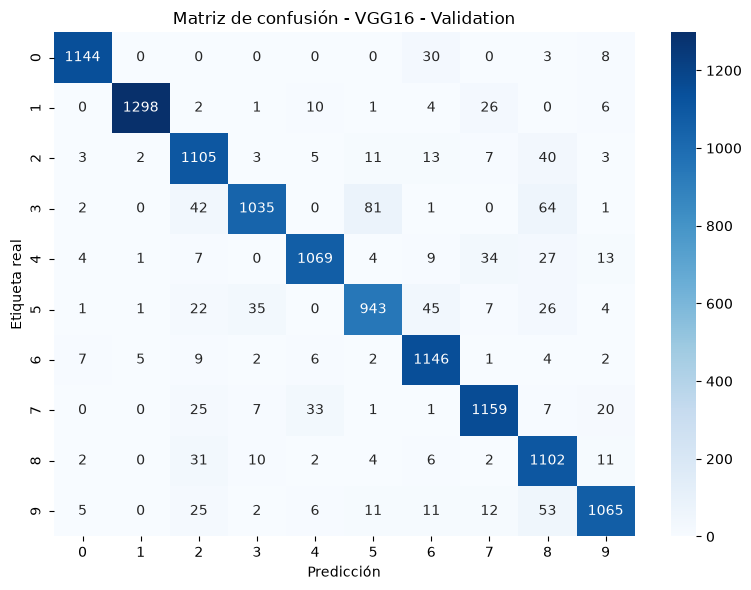

In [32]:
# ### 13. Evaluación sobre validation
#
# Obtenemos la clase con mayor probabilidad para cada imagen.

# %%
y_val_prob = model.predict(
    x_val_processed,
    batch_size=batch_size,
    verbose=0
)

y_val_pred = np.argmax(y_val_prob, axis=1)
y_val_true = np.argmax(y_val, axis=1)

print(
    classification_report(
        y_val_true,
        y_val_pred,
        labels=np.arange(10),
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión - VGG16 - Validation")
plt.tight_layout()
plt.show()


*El siguiente paso es aplicar el modelo sobre test set y evaluarlo*

### 2. Fine-Tuning

In [ ]:
from tensorflow.keras.applications import VGG16 

pre_trained_model = VGG16(
    input_shape=(32, 32, 3),
    include_top=False,
    weights="imagenet"
)

pre_trained_model.trainable = True 

set_trainable = False 

for layer in pre_trained_model.layers: 
    if layer.name == 'block5_conv3':     #identifica 'block5_conv3' y cambia: set_trinable a True
        set_trainable = True 
    if set_trainable:                  #ahora que 'block5_conv3' tiene set_trainable = True haz la capa entrenable (cambia layer.trainable a True)
        layer.trainable = True 
    else: 
        layer.trainable = False

Este código indica que las capas del block5 deben ser entremnbles mediante la asignacion del valor `True` al parámetro `set_trainable` de cada capa

**Importante:** Si indicara `layer.name == 'block5_conv1'` significaria que estoy entrenando todo el bloque 5, ya que como las capas convolucionales están conectadas, entrenar la conv1 implicaria actualizar los pesos de las 3 capas

In [15]:
pre_trained_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 2,359,808 (9.00 MB)

 Non-trainable params: 12,354,880 (47.13 MB)

In [16]:
modelFT = Sequential()
modelFT.add(pre_trained_model)
modelFT.add(Flatten())
modelFT.add(Dense(256, activation='relu'))
modelFT.add(Dense(10, activation='softmax'))

modelFT.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 2,493,706 (9.51 MB)

 Non-trainable params: 12,354,880 (47.13 MB)

In [17]:
modelFT.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# ### 10. Entrenamiento: Feature Extraction

# %%
batch_size = 64

train_generator = datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=True,
    seed=42
)

history = modelFT.fit(
    train_generator,
    epochs=15,
    validation_data=(x_val_processed, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 240s 317ms/step - accuracy: 0.6329 - loss: 2.2824 - val_accuracy: 0.8486 - val_loss: 0.5037
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 236s 315ms/step - accuracy: 0.8256 - loss: 0.6804 - val_accuracy: 0.8951 - val_loss: 0.3454
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 234s 312ms/step - accuracy: 0.8714 - loss: 0.4870 - val_accuracy: 0.9118 - val_loss: 0.2857
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 232s 309ms/step - accuracy: 0.8935 - loss: 0.3883 - val_accuracy: 0.9319 - val_loss: 0.2242
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 233s 311ms/step - accuracy: 0.9054 - loss: 0.3496 - val_accuracy: 0.9376 - val_loss: 0.2002
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 242s 322ms/step - accuracy: 0.9148 - loss: 0.3058 - val_accuracy: 0.9420 - val_loss: 0.1868
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 234s 312ms/step - accuracy: 0.9234 - loss: 0.2684 - val_accuracy: 0.9492 - val_loss: 0.1623
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 237s 316ms/step - accuracy: 0.9276 -

In [18]:
# ### 11. Evaluación sobre train y validation
#
# Evaluamos train sin aumentos aleatorios, para que la comparación
# con validation sea más consistente.

# %%
train_eval_generator = eval_datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=False
)

train_loss, train_accuracy = modelFT.evaluate(
    train_eval_generator,
    verbose=1
)

val_loss, val_accuracy = modelFT.evaluate(
    x_val_processed,
    y_val,
    batch_size=batch_size,
    verbose=1
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print("-" * 80)
print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

750/750 ━━━━━━━━━━━━━━━━━━━━ 105s 139ms/step - accuracy: 0.9701 - loss: 0.0928
188/188 ━━━━━━━━━━━━━━━━━━━━ 37s 193ms/step - accuracy: 0.9699 - loss: 0.1015
Train Loss: 0.0928
Validation Loss: 0.1015
--------------------------------------------------------------------------------
Train Accuracy: 0.9701
Validation Accuracy: 0.9699


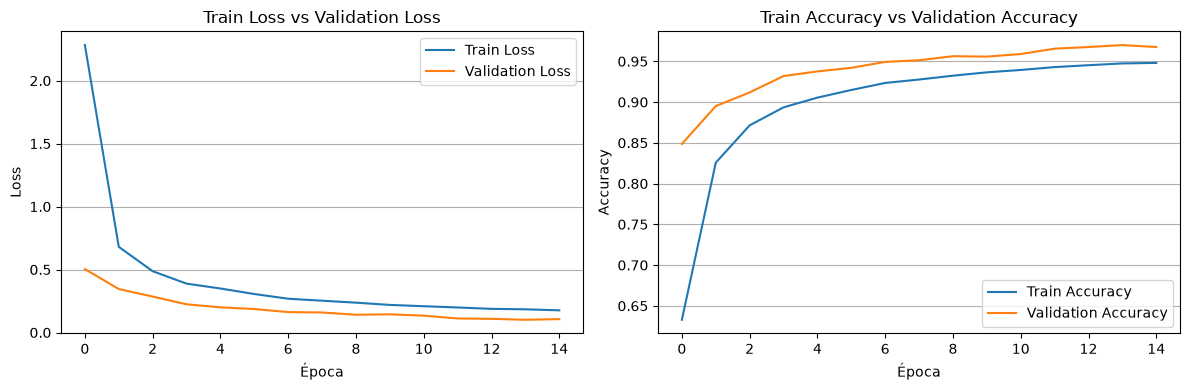

In [19]:
# ### 12. Visualización de las curvas de aprendizaje

# %%
df_history = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pérdida
axes[0].plot(df_history["loss"], label="Train Loss")
axes[0].plot(df_history["val_loss"], label="Validation Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].set_title("Train Loss vs Validation Loss")
axes[0].grid(True, axis="y")
axes[0].legend()

# Exactitud
axes[1].plot(df_history["accuracy"], label="Train Accuracy")
axes[1].plot(df_history["val_accuracy"], label="Validation Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Train Accuracy vs Validation Accuracy")
axes[1].grid(True, axis="y")
axes[1].legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1185
           1       0.99      0.98      0.99      1348
           2       0.98      0.96      0.97      1192
           3       0.94      0.99      0.96      1226
           4       0.97      0.97      0.97      1168
           5       0.96      0.96      0.96      1084
           6       0.99      0.96      0.97      1184
           7       0.97      0.98      0.97      1253
           8       0.97      0.94      0.96      1170
           9       0.96      0.97      0.96      1190

    accuracy                           0.97     12000
   macro avg       0.97      0.97      0.97     12000
weighted avg       0.97      0.97      0.97     12000



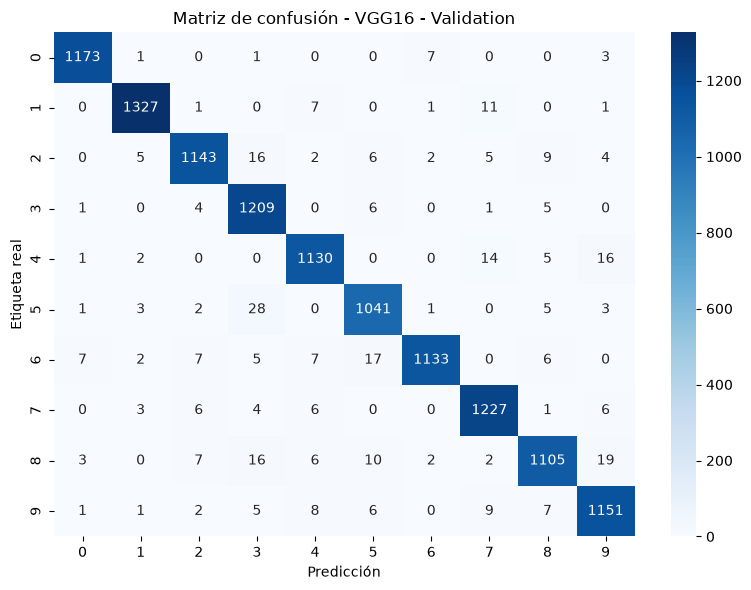

In [20]:
# ### 13. Evaluación sobre validation
#
# Obtenemos la clase con mayor probabilidad para cada imagen.

# %%
y_val_prob = modelFT.predict(
    x_val_processed,
    batch_size=batch_size,
    verbose=0
)

y_val_pred = np.argmax(y_val_prob, axis=1)
y_val_true = np.argmax(y_val, axis=1)

print(
    classification_report(
        y_val_true,
        y_val_pred,
        labels=np.arange(10),
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión - VGG16 - Validation")
plt.tight_layout()
plt.show()